# Import library

In [1]:
import pandas as pd
from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt
import os
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler


/opt/conda/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/conda/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


# Import datasets

In [2]:
fileDir = "./Data/"
fileName = "pro_data_common_dis.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

#Z-score transformation
print('Before:')
display(temp.iloc[:, :15].describe())

temp2 = temp.copy()
scaler = StandardScaler(copy=True, with_mean=True, with_std=True)
tempA = scaler.fit_transform(temp2)#axis: column
tempDF = pd.DataFrame(data=tempA, index=temp2.index, columns=temp2.columns)

print('After:')
display(tempDF)
display(tempDF.iloc[:, :15].describe())

pro_data_dis = tempDF 

,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P23467,P23471,Q9HCK4,P31949,Q9Y286,P17405,P16035,O00300,O14836,O75888
PE_R345_001,-0.692179,0.014487,0.020949,0.756419,-6.905352,-1.666651,0.110046,0.232470,0.976434,0.333324,...,0.149422,0.109952,0.043224,-0.113186,-0.173051,-0.188583,-0.500891,-0.449172,0.256756,-0.047204
PE_R345_002,-0.369176,0.684363,0.107959,0.226569,-0.895626,0.109439,-0.303590,0.920268,0.553696,0.262794,...,0.138417,0.010032,-0.375500,-0.283585,-0.078765,-0.462358,-0.050531,-0.265815,-0.329777,-0.093153
PE_R345_003,-2.394688,-0.344467,0.324566,-0.662745,-0.618029,0.400878,0.781645,-1.083091,1.017989,-0.476468,...,0.297876,0.215148,-0.298019,0.230742,-0.446693,-0.238989,-0.149903,-0.368405,-0.777895,0.263554
PE_R345_004,0.639747,-0.618308,-6.105701,-0.604463,-0.660618,0.948256,0.658751,-5.307591,1.752600,0.242457,...,0.248981,-0.836763,-0.025668,0.707852,0.094298,0.143641,-1.107125,-0.370944,0.038383,-0.088797
PE_R345_005,-0.820588,1.828802,0.743556,0.944768,0.374343,-0.004282,0.768770,-0.472727,2.379818,0.355268,...,-0.719388,-0.386761,-0.057828,-0.293611,-0.615043,0.109108,-0.304250,-0.075093,-0.269609,-0.345198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,0.562479,0.149407,-0.096848,-0.511773,1.161234,0.435930,0.034395,1.648347,-1.236074,0.230566,...,-0.024150,-0.454680,-0.295363,-0.015434,0.008547,-0.302837,0.642489,-0.415615,0.223440,0.364843
PE_R345_117,0.479147,-2.197393,-1.046985,-0.710840,0.222618,-1.514128,-0.754977,-0.603034,-0.655577,-0.820657,...,0.024235,0.431829,-0.105863,-0.214236,-0.203326,0.082807,0.208317,0.596235,0.059546,0.050563
PE_R345_118,-0.224505,1.418296,-0.638240,-0.916879,0.022731,-0.256893,1.527204,0.002125,0.944555,0.227068,...,0.024150,0.177696,0.283866,-0.576475,-0.369869,-0.202398,-0.477743,-0.116504,-0.035482,-0.582310
PE_R345_119,2.850504,2.163309,-0.020949,0.127092,1.120073,0.066293,-0.140565,0.364944,1.119934,-0.804565,...,-0.242695,0.292754,0.197778,-0.129258,0.404362,0.196653,0.153734,0.130001,-0.233168,0.494186


Before:


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,Q5VVH5,Q08493,A5LHX3,Q9Y572,Q8IUD6
count,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000,119.000000
mean,0.149922,0.102477,-0.206834,-0.063302,-0.072779,-0.071963,0.007782,-0.720812,-0.133301,0.133156,0.031783,0.121607,-0.156218,-0.157010,-0.120975
std,1.333804,2.081257,1.251925,0.866898,1.629453,0.901540,0.996551,2.331576,2.014895,0.822135,0.672086,0.541910,2.499572,1.091915,0.901629
min,-2.858397,-7.285339,-6.105701,-2.223377,-6.905352,-3.407961,-2.396511,-5.897850,-7.404639,-1.176217,-1.083751,-0.693255,-7.444348,-3.913881,-2.919381
25%,-0.780000,-0.804311,-0.864835,-0.610567,-0.840935,-0.512136,-0.656042,-1.036516,-1.019647,-0.432103,-0.428787,-0.146748,-1.260060,-0.882519,-0.567402
50%,0.001608,0.008569,-0.000707,-0.003123,0.001914,0.004282,0.005773,-0.002125,0.042358,-0.015400,-0.003200,0.006733,0.006071,0.003002,-0.002080
75%,0.839267,0.883940,0.481992,0.437380,0.656578,0.468912,0.460787,0.793138,1.062602,0.401160,0.297769,0.181470,1.070485,0.558773,0.403097
max,3.720056,7.813354,2.514447,3.612354,7.815486,1.757884,4.453020,2.921238,4.315825,3.527744,3.758375,2.301277,5.916202,1.889620,3.429907


After:


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P23467,P23471,Q9HCK4,P31949,Q9Y286,P17405,P16035,O00300,O14836,O75888
PE_R345_001,-0.634023,-0.042456,0.182715,0.949577,-4.210899,-1.776328,0.103051,0.410586,0.553095,0.244503,...,0.223994,0.191764,0.079468,-0.252938,-0.332760,-0.416982,-1.025418,-1.112749,0.450507,-0.208498
PE_R345_002,-0.390832,0.280766,0.252510,0.335791,-0.507119,0.202064,-0.313771,0.706826,0.342401,0.158352,...,0.202684,-0.044168,-1.306822,-0.595321,-0.147103,-0.820948,-0.186227,-0.727364,-0.718082,-0.357636
PE_R345_003,-1.915851,-0.215655,0.426261,-0.694405,-0.336036,0.526699,0.779824,-0.156037,0.573806,-0.744648,...,0.511434,0.440150,-1.050301,0.438114,-0.871579,-0.491358,-0.371395,-0.942990,-1.610900,0.800139
PE_R345_004,0.368792,-0.347786,-4.731761,-0.626889,-0.362284,1.136425,0.655983,-1.975562,0.939938,0.133510,...,0.416762,-2.043608,-0.148614,1.396769,0.193668,0.073226,-2.155065,-0.948328,0.015427,-0.343499
PE_R345_005,-0.730703,0.832970,0.762352,1.167764,0.275560,0.075390,0.766851,0.106852,1.252544,0.271307,...,-1.458222,-0.981069,-0.255087,-0.615466,-1.203070,0.022270,-0.659001,-0.326499,-0.598206,-1.175709
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,0.310617,0.022644,0.088225,-0.519515,0.760519,0.565744,0.026818,1.020415,-0.549624,0.118986,...,-0.112082,-1.141439,-1.041506,-0.056526,0.024819,-0.585569,1.105136,-1.042220,0.384130,1.128897
PE_R345_117,0.247875,-1.109711,-0.673926,-0.750118,0.182052,-1.606432,-0.768636,0.050728,-0.260304,-1.165071,...,-0.018398,0.951775,-0.414121,-0.455978,-0.392373,-0.016536,0.296107,1.084520,0.057593,0.108826
PE_R345_118,-0.281909,0.634897,-0.346052,-0.988797,0.058863,-0.205994,1.531127,0.311374,0.537206,0.114713,...,-0.018563,0.351720,0.876174,-1.183823,-0.720306,-0.437368,-0.982286,-0.413538,-0.131739,-1.945313
PE_R345_119,2.033283,0.994373,0.149107,0.220555,0.735152,0.154004,-0.149490,0.467643,0.624615,-1.145416,...,-0.535235,0.623392,0.591159,-0.285231,0.804205,0.151447,0.194398,0.104574,-0.525603,1.548712


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,Q5VVH5,Q08493,A5LHX3,Q9Y572,Q8IUD6
count,1.190000e+02,1.190000e+02,1.190000e+02,1.190000e+02,1.190000e+02,119.000000,1.190000e+02,1.190000e+02,1.190000e+02,1.190000e+02,119.000000,119.000000,1.190000e+02,1.190000e+02,1.190000e+02
mean,1.119553e-17,3.288686e-17,-1.562709e-17,2.379049e-17,4.198322e-18,0.000000,-6.997204e-18,9.049717e-17,-2.798882e-18,-1.492737e-17,0.000000,0.000000,-3.265362e-17,2.798882e-17,3.265362e-18
std,1.004228e+00,1.004228e+00,1.004228e+00,1.004228e+00,1.004228e+00,1.004228,1.004228e+00,1.004228e+00,1.004228e+00,1.004228e+00,1.004228,1.004228,1.004228e+00,1.004228e+00,1.004228e+00
min,-2.264981e+00,-3.564699e+00,-4.731761e+00,-2.502265e+00,-4.210899e+00,-3.715979,-2.422815e+00,-2.229791e+00,-3.624051e+00,-1.599384e+00,-1.666826,-1.510044,-2.928080e+00,-3.455172e+00,-3.116845e+00
25%,-7.001438e-01,-4.375348e-01,-5.278138e-01,-6.339608e-01,-4.734128e-01,-0.490310,-6.689386e-01,-1.359763e-01,-4.417566e-01,-6.904565e-01,-0.688181,-0.497296,-4.434799e-01,-6.672464e-01,-4.972269e-01
50%,-1.116664e-01,-4.531151e-02,1.653436e-01,6.971246e-02,4.603323e-02,0.084930,-2.025276e-03,3.095442e-01,8.754873e-02,-1.814589e-01,-0.052271,-0.212877,6.520140e-02,1.471622e-01,1.324240e-01
75%,5.190118e-01,3.770643e-01,5.525399e-01,5.799978e-01,4.495011e-01,0.602483,4.564941e-01,6.520702e-01,5.960406e-01,3.273641e-01,0.397435,0.110934,4.928403e-01,6.583008e-01,5.837072e-01
max,2.687973e+00,3.720580e+00,2.182868e+00,4.257937e+00,4.861520e+00,2.038273,4.479483e+00,1.568659e+00,2.217454e+00,4.146451e+00,5.568258,4.039210,2.439656e+00,1.882274e+00,3.954947e+00


In [3]:
fileDir = "./Data/"
fileName = "pro_data_common_val.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

#Z-score transformation
print('Before:')
display(temp.iloc[:, :15].describe())

temp2 = temp.copy()
scaler = StandardScaler(copy=True, with_mean=True, with_std=True)
tempA = scaler.fit_transform(temp2)#axis: column
tempDF = pd.DataFrame(data=tempA, index=temp2.index, columns=temp2.columns)

print('After:')
display(tempDF)
display(tempDF.iloc[:, :15].describe())

pro_data_val = tempDF 

,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P33316,Q92597,Q9NRA1,Q15643,P35520,Q15262,P25685,Q9Y570,Q6UB99,P49789
PE_R478_001,-0.250458,-0.391125,-0.252621,0.150167,-0.047767,-0.316298,-0.044654,0.516400,1.150911,-0.027801,...,0.734304,0.110696,0.058819,-0.250565,-0.145040,-0.262231,-0.306965,-0.328111,0.216998,-0.101624
PE_R478_002,0.650528,1.724016,0.550598,2.128050,-0.040240,1.335081,0.269637,-0.182468,-0.071227,-0.251168,...,3.043780,0.944960,-0.074905,-0.028470,-0.112292,0.009771,0.605862,1.732763,0.050603,-0.070623
PE_R478_003,-0.391076,0.827442,0.564473,0.000000,2.602543,0.168998,-0.149231,0.027239,1.254693,1.006632,...,-0.175562,0.927932,0.247506,1.032951,-0.320810,0.012949,0.187431,-0.014972,-0.272747,0.060313
PE_R478_004,0.070462,-0.096654,-0.382649,0.026322,0.003985,0.493930,-0.002798,-0.114333,-0.118398,1.043088,...,-0.603477,-0.421595,0.008789,-0.258851,1.877652,0.111118,0.459926,0.325601,3.782591,-0.063099
PE_R478_005,0.378868,0.522751,2.066188,1.183532,0.329253,1.291015,1.488711,1.123200,0.775145,-0.163659,...,2.440574,0.711782,0.082763,1.664001,1.675150,0.773179,0.788874,0.492789,0.191108,0.228033
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,2.090906,0.937016,0.432914,0.422205,-0.034455,0.301893,-0.417816,0.567447,-0.038375,0.396514,...,-0.318979,0.567542,-0.176940,-1.468123,0.858104,0.097731,-0.573343,-0.164230,0.004873,-0.195060
PE_R478_397,0.652913,-0.084482,0.471556,0.067670,0.048786,1.311366,0.047220,-0.000537,-0.037272,0.503015,...,0.953380,2.234465,0.233921,-0.020321,3.746860,0.025703,0.553025,0.145132,0.019710,2.857327
PE_R478_398,0.025657,-0.369096,-0.940943,-0.833491,-0.035938,-0.282643,0.902980,-0.354449,-0.378662,0.830012,...,0.373973,-0.330692,0.003094,0.760417,-0.094866,-0.042590,0.295296,0.252283,-0.597332,0.102647
PE_R478_399,0.115515,0.252649,0.799482,-0.555303,-0.095176,0.147232,-0.232622,0.275772,-0.090074,-0.284806,...,-0.294149,2.978748,-0.111313,-0.910355,0.684876,-0.089939,-0.454858,-0.286652,-0.528971,-0.131158


Before:


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,Q5VVH5,Q08493,A5LHX3,Q9Y572,Q8IUD6
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,0.044661,0.336845,0.106689,0.017878,0.063028,0.013972,0.131581,0.033301,0.269420,0.265993,0.338463,0.099477,0.263182,0.078632,0.039049
std,0.312329,1.175544,0.698146,0.614017,0.330080,0.544660,0.572410,0.421443,0.818394,0.971984,1.484944,0.742275,1.600096,0.743092,0.468379
min,-0.692585,-1.351627,-1.662149,-1.620190,-0.380384,-2.121668,-0.733173,-1.044924,-0.676899,-1.438927,-1.452573,-1.583654,-2.978228,-1.819812,-2.063858
25%,-0.121814,-0.276956,-0.380736,-0.362140,-0.071999,-0.301486,-0.193354,-0.181774,-0.176691,-0.338836,-0.573816,-0.281575,-0.953322,-0.456835,-0.196118
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.152742,0.497758,0.471577,0.337887,0.097237,0.326000,0.277358,0.203204,0.325661,0.591441,0.842479,0.325019,1.129120,0.547989,0.248926
max,2.877360,8.659297,3.153816,2.627490,3.912854,2.898588,3.707043,3.688811,4.352708,5.260313,10.619192,5.777851,7.035730,3.476466,2.166991


After:


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P33316,Q92597,Q9NRA1,Q15643,P35520,Q15262,P25685,Q9Y570,Q6UB99,P49789
PE_R478_001,-0.946087,-0.620042,-0.515311,0.215720,-0.336085,-0.607141,-0.308269,1.147738,1.078454,-0.302643,...,0.991835,-0.146533,0.138862,-0.370328,-0.394409,-1.094301,-0.545054,-0.642443,-0.059930,-0.443364
PE_R478_002,1.942274,1.181510,0.636641,3.440991,-0.313253,2.428617,0.241487,-0.512623,-0.416762,-0.532737,...,4.324127,0.591903,-0.332623,-0.102273,-0.358944,-0.188166,0.680855,2.283186,-0.234401,-0.378734
PE_R478_003,-1.396876,0.417861,0.656539,-0.029152,7.703317,0.284987,-0.491196,-0.014402,1.205424,0.762946,...,-0.320990,0.576831,0.804139,1.178798,-0.584756,-0.177579,0.118910,-0.197909,-0.573444,-0.105761
PE_R478_004,0.082712,-0.369229,-0.701792,0.013769,-0.179100,0.882315,-0.235054,-0.350748,-0.474473,0.800499,...,-0.938420,-0.617682,-0.037532,-0.380329,1.796045,0.149458,0.484866,0.285570,3.678711,-0.363048
PE_R478_005,1.071392,0.158344,2.810250,1.900796,0.807562,2.347610,2.373889,2.589366,0.618725,-0.442593,...,3.453774,0.385509,0.223285,1.940439,1.576748,2.355026,0.926638,0.522911,-0.087076,0.243898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,6.559809,0.511190,0.467862,0.659325,-0.295705,0.529290,-0.961004,1.269017,-0.376569,0.134452,...,-0.527924,0.257837,-0.692380,-1.839849,0.691937,0.104862,-0.902795,-0.409796,-0.282350,-0.638158
PE_R478_397,1.949920,-0.358861,0.523281,0.081195,-0.043202,2.385021,-0.147564,-0.080393,-0.375220,0.244160,...,1.307935,1.733288,0.756241,-0.092438,3.820285,-0.135088,0.609897,0.029376,-0.266793,5.725392
PE_R478_398,-0.060925,-0.601279,-1.502479,-1.388300,-0.300203,-0.545272,1.349330,-0.921212,-0.792892,0.581006,...,0.471921,-0.537221,-0.057613,0.849866,-0.340072,-0.362598,0.263771,0.181488,-0.913782,-0.017504
PE_R478_399,0.227142,-0.071713,0.993582,-0.934668,-0.479894,0.244974,-0.637064,0.576059,-0.439820,-0.567388,...,-0.492096,2.392078,-0.460990,-1.166656,0.504341,-0.520334,-0.743672,-0.583587,-0.842103,-0.504936


,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,Q5VVH5,Q08493,A5LHX3,Q9Y572,Q8IUD6
count,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02,3.980000e+02
mean,4.463208e-18,-1.785283e-17,2.677925e-17,1.785283e-17,4.463208e-18,-2.677925e-17,-5.355850e-17,-1.394753e-17,-1.785283e-17,-3.570567e-17,-8.926416e-18,1.785283e-17,-1.785283e-17,-8.926416e-18,8.926416e-18
std,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00,1.001259e+00
min,-2.363447e+00,-1.438140e+00,-2.536810e+00,-2.671145e+00,-1.345038e+00,-3.925984e+00,-1.512626e+00,-2.561632e+00,-1.157766e+00,-1.756269e+00,-1.207649e+00,-2.270385e+00,-2.028309e+00,-2.558006e+00,-4.495403e+00
25%,-5.336815e-01,-5.227990e-01,-6.990479e-01,-6.196834e-01,-4.095893e-01,-5.799119e-01,-5.683754e-01,-5.109734e-01,-5.457906e-01,-6.230457e-01,-6.151257e-01,-5.140028e-01,-7.612262e-01,-7.215004e-01,-5.027179e-01
50%,-1.431737e-01,-2.869045e-01,-1.530092e-01,-2.915243e-02,-1.911894e-01,-2.568544e-02,-2.301610e-01,-7.911709e-02,-3.296199e-01,-2.740044e-01,-2.282169e-01,-1.341848e-01,-1.646858e-01,-1.059507e-01,-8.347445e-02
75%,3.464818e-01,1.370564e-01,5.233114e-01,5.218292e-01,1.037673e-01,5.736051e-01,2.549929e-01,4.036530e-01,6.880817e-02,3.352501e-01,3.398447e-01,3.042352e-01,5.418596e-01,6.324224e-01,4.486562e-01
max,9.081005e+00,7.088570e+00,4.370092e+00,4.255413e+00,1.167799e+01,5.302838e+00,6.254193e+00,8.684709e+00,4.995668e+00,5.144739e+00,6.932024e+00,7.659593e+00,4.237915e+00,4.578316e+00,4.548922e+00


## メタデータ

### Validation

In [4]:
fileDir = "./Data/"
fileName = "pro_sample.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None

temp["Cohort"] = "Validation"

display(temp)

pro_sample_val = temp

,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R,Cohort
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0,Validation
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0,Validation
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0,Validation
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0,Validation
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0,Validation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0,Validation
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0,Validation
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0,Validation
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0,Validation


### Discovery

In [5]:
fileDir = "../Proteomics/Data/"
fileName = "pro_sample.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path)
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None

temp["Cohort"] = "Discovery"

display(temp)

pro_sample_dis = temp

,groupset1,groupset2,groupset3,progress,sex,fvage,CaCo_status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,Cohort
PE_R345_001,2,0,1,NaN,2,52,control,NaN,NaN,Former,34,Current,1,21,0,Discovery
PE_R345_002,1,1,2,440.0,1,56,case,C259,8140/39,Former,26,Current,31,23,0,Discovery
PE_R345_003,1,1,2,430.0,1,62,case,C259,8211/32,Current,44,Current,6,19,0,Discovery
PE_R345_004,1,1,2,440.0,1,39,case,C251,8500/39,Never,0,Never,0,24,0,Discovery
PE_R345_005,2,1,3,440.0,2,48,case,C251,8140/39,Never,0,Never,0,17,0,Discovery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,1,0,0,NaN,1,59,control,NaN,NaN,Current,78,Current,69,26,0,Discovery
PE_R345_117,2,0,1,NaN,2,64,control,NaN,NaN,Current,66,Current,21,17,0,Discovery
PE_R345_118,2,1,3,430.0,2,39,case,C251,8150/39,Former,3,Current,46,21,0,Discovery
PE_R345_119,2,1,3,440.0,2,51,case,C250,8140/39,Never,0,Former,2,19,0,Discovery


# DiscoveryとValidationを統合

## analyte data

In [6]:
temp = pd.concat(
    [pro_data_val, pro_data_dis],
    axis=0,
    ignore_index=False  # インデックスを保持
)
display(temp)
pro_data = temp

,P24385,Q8N2Z9,P11308,Q9UI08,Q9UH90,P57764,Q9UQL6,P01574,K9M1U5,Q14626,...,P33316,Q92597,Q9NRA1,Q15643,P35520,Q15262,P25685,Q9Y570,Q6UB99,P49789
PE_R478_001,-0.946087,-0.620042,-0.515311,0.215720,-0.336085,-0.607141,-0.308269,1.147738,1.078454,-0.302643,...,0.991835,-0.146533,0.138862,-0.370328,-0.394409,-1.094301,-0.545054,-0.642443,-0.059930,-0.443364
PE_R478_002,1.942274,1.181510,0.636641,3.440991,-0.313253,2.428617,0.241487,-0.512623,-0.416762,-0.532737,...,4.324127,0.591903,-0.332623,-0.102273,-0.358944,-0.188166,0.680855,2.283186,-0.234401,-0.378734
PE_R478_003,-1.396876,0.417861,0.656539,-0.029152,7.703317,0.284987,-0.491196,-0.014402,1.205424,0.762946,...,-0.320990,0.576831,0.804139,1.178798,-0.584756,-0.177579,0.118910,-0.197909,-0.573444,-0.105761
PE_R478_004,0.082712,-0.369229,-0.701792,0.013769,-0.179100,0.882315,-0.235054,-0.350748,-0.474473,0.800499,...,-0.938420,-0.617682,-0.037532,-0.380329,1.796045,0.149458,0.484866,0.285570,3.678711,-0.363048
PE_R478_005,1.071392,0.158344,2.810250,1.900796,0.807562,2.347610,2.373889,2.589366,0.618725,-0.442593,...,3.453774,0.385509,0.223285,1.940439,1.576748,2.355026,0.926638,0.522911,-0.087076,0.243898
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,0.310617,0.022644,0.088225,-0.519515,0.760519,0.565744,0.026818,1.020415,-0.549624,0.118986,...,0.832090,0.658578,-1.208707,0.595930,0.145890,-0.242855,0.000613,-0.248631,-0.207129,0.829610
PE_R345_117,0.247875,-1.109711,-0.673926,-0.750118,0.182052,-1.606432,-0.768636,0.050728,-0.260304,-1.165071,...,-0.635113,-0.102472,-1.576644,-3.024162,-0.372383,-1.351340,-0.648315,-0.584791,0.454445,-0.567338
PE_R345_118,-0.281909,0.634897,-0.346052,-0.988797,0.058863,-0.205994,1.531127,0.311374,0.537206,0.114713,...,-1.370584,0.803621,-0.891933,-0.484680,-1.088376,-0.510715,-1.878555,-0.868902,-0.950153,1.112043
PE_R345_119,2.033283,0.994373,0.149107,0.220555,0.735152,0.154004,-0.149490,0.467643,0.624615,-1.145416,...,-0.168230,-0.082962,0.856209,-0.290248,1.635638,1.184619,-0.672496,-1.140312,-0.779655,-0.371855


## meta data

In [7]:
display(pro_sample_dis)
display(pro_sample_val)

,groupset1,groupset2,groupset3,progress,sex,fvage,CaCo_status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,Cohort
PE_R345_001,2,0,1,NaN,2,52,control,NaN,NaN,Former,34,Current,1,21,0,Discovery
PE_R345_002,1,1,2,440.0,1,56,case,C259,8140/39,Former,26,Current,31,23,0,Discovery
PE_R345_003,1,1,2,430.0,1,62,case,C259,8211/32,Current,44,Current,6,19,0,Discovery
PE_R345_004,1,1,2,440.0,1,39,case,C251,8500/39,Never,0,Never,0,24,0,Discovery
PE_R345_005,2,1,3,440.0,2,48,case,C251,8140/39,Never,0,Never,0,17,0,Discovery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,1,0,0,NaN,1,59,control,NaN,NaN,Current,78,Current,69,26,0,Discovery
PE_R345_117,2,0,1,NaN,2,64,control,NaN,NaN,Current,66,Current,21,17,0,Discovery
PE_R345_118,2,1,3,430.0,2,39,case,C251,8150/39,Former,3,Current,46,21,0,Discovery
PE_R345_119,2,1,3,440.0,2,51,case,C250,8140/39,Never,0,Former,2,19,0,Discovery


,progress,sex,fvage,CaCo_Status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,CA19_9,sIL2R,Cohort
PE_R478_001,0,1,58,0,NaN,NaN,2,8,1,25,20,0,4.100,134.0,Validation
PE_R478_002,0,1,62,0,NaN,NaN,2,10,1,33,23,0,1.999,5500.0,Validation
PE_R478_003,0,1,68,0,NaN,NaN,1,24,3,0,22,0,2.700,259.0,Validation
PE_R478_004,0,2,70,0,NaN,NaN,3,0,3,0,26,0,3.800,208.0,Validation
PE_R478_005,440,1,59,1,C252,81403.0,3,0,3,0,29,0,1200.000,1181.0,Validation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_396,410,1,63,1,C250,84533.0,1,27,3,0,26,1,1.999,263.0,Validation
PE_R478_397,410,2,64,1,C250,85003.0,3,0,1,12,22,0,1.999,257.0,Validation
PE_R478_398,0,1,38,0,NaN,NaN,2,13,1,4,29,0,2.100,257.0,Validation
PE_R478_399,410,2,47,1,C250,85003.0,3,0,1,2,21,0,16.900,216.0,Validation


In [8]:
# Discovery側
meta_dis = pro_sample_dis[[
    "fvage",
    "groupset2",
    "Cohort",
    "quant_drink_gr",
    "py",
    "hx_dm",
    "sex"
]].rename(columns={"groupset2": "CaCo_Status"})

# Validation側
meta_val = pro_sample_val[[
    "fvage",
    "CaCo_Status",
    "Cohort",
    "quant_drink_gr",
    "py",
    "hx_dm",
    "sex"
]]

# 縦に結合
pro_sample = pd.concat([meta_dis, meta_val], axis=0)

display(pro_sample)

,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
PE_R345_001,52,0,Discovery,1,34,0,2
PE_R345_002,56,1,Discovery,31,26,0,1
PE_R345_003,62,1,Discovery,6,44,0,1
PE_R345_004,39,1,Discovery,0,0,0,1
PE_R345_005,48,1,Discovery,0,0,0,2
...,...,...,...,...,...,...,...
PE_R478_396,63,1,Validation,0,27,1,1
PE_R478_397,64,1,Validation,12,0,0,2
PE_R478_398,38,0,Validation,4,13,0,1
PE_R478_399,47,1,Validation,2,0,0,2


# WELLの値の補正がきちんとできているかを確認

## Import dataset: validation

In [9]:
fileDir = "./ssd/PE_R478/NPXfiles/original/"
fileName = "PE_R478_AN01_NPX_2026-04-01.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path, sep=";")
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_plate = temp

,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,UniProt,Assay,AssayType,Panel,Block,...,Normalization,PCNormalizedNPX,AssayQC,SampleQC,SoftwareVersion,SoftwareName,PanelDataArchiveVersion,PreProcessingVersion,PreProcessingSoftware,InstrumentType
PE_R478_362,SAMPLE,A1,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_004,SAMPLE,A2,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_194,SAMPLE,A3,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_281,SAMPLE,A4,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_135,SAMPLE,A5,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_364,SAMPLE,H5,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.288263,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_189,SAMPLE,H6,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.181319,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_029,SAMPLE,H7,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.312288,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
NC2,NEGATIVE_CONTROL,H11,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,-1.430350,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus


In [10]:
display(pro_plate)

,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,UniProt,Assay,AssayType,Panel,Block,...,Normalization,PCNormalizedNPX,AssayQC,SampleQC,SoftwareVersion,SoftwareName,PanelDataArchiveVersion,PreProcessingVersion,PreProcessingSoftware,InstrumentType
PE_R478_362,SAMPLE,A1,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_004,SAMPLE,A2,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_194,SAMPLE,A3,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_281,SAMPLE,A4,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_135,SAMPLE,A5,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,Intensity,0.000000,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_364,SAMPLE,H5,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.288263,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_189,SAMPLE,H6,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.181319,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
PE_R478_029,SAMPLE,H7,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,0.312288,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus
NC2,NEGATIVE_CONTROL,H11,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,Intensity,-1.430350,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus


In [11]:
print(pro_plate["PlateID"].unique())

<ArrowStringArray>
['PlateLayout_PE_R478_L01', 'PlateLayout_PE_R478_L02',
 'PlateLayout_PE_R478_L03', 'PlateLayout_PE_R478_L04',
 'PlateLayout_PE_R478_L05']
Length: 5, dtype: str


In [22]:
pro_plate["WellRow"] = pro_plate["WellID"].str[0]
pro_plate["WellCol"] = pro_plate["WellID"].str[1:].astype(int)

display(pro_plate)

,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,UniProt,Assay,AssayType,Panel,Block,...,AssayQC,SampleQC,SoftwareVersion,SoftwareName,PanelDataArchiveVersion,PreProcessingVersion,PreProcessingSoftware,InstrumentType,WellRow,WellCol
PE_R478_362,SAMPLE,A1,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,A,1
PE_R478_004,SAMPLE,A2,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,A,2
PE_R478_194,SAMPLE,A3,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,A,3
PE_R478_281,SAMPLE,A4,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,A,4
PE_R478_135,SAMPLE,A5,PlateLayout_PE_R478_L01,R10002,OID50003,EXT1,Extension control,ext_ctrl,Reveal,1,...,NaN,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,A,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_364,SAMPLE,H5,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,H,5
PE_R478_189,SAMPLE,H6,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,H,6
PE_R478_029,SAMPLE,H7,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,H,7
NC2,NEGATIVE_CONTROL,H11,PlateLayout_PE_R478_L05,R10002,OID51014,Q8WV99,ZFAND2B,assay,Reveal,1,...,PASS,PASS,1.3.0,NPX Map,1.8.0,5.1.0,ngs2counts,Illumina NovaSeq X Plus,H,11


In [12]:
temp = pro_plate.reset_index().rename(columns={"index": "SampleID"})
temp = temp[
    ["SampleID", "WellID", "PlateID", "NPX"]
]
temp = temp[
    ~temp["SampleID"].str.match(r"^(PC|NC|SC)", na=False)
]
tempL = pro_sample_val[[
    "fvage", "CaCo_Status", "Cohort", "quant_drink_gr", "py", "hx_dm", "sex"
]].copy()

temp2 = temp.merge(
    tempL,
    left_on="SampleID",
    right_index=True,
    how="left"
)

temp3 = temp2.drop_duplicates(subset="SampleID")

temp2.set_index(temp2.columns[0],inplace=True)
temp3.set_index(temp3.columns[0],inplace=True)

display(temp2)
pro_Well_val = temp2

display(temp3)
metadata_val = temp3

,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
SampleID,,,,,,,,,,
PE_R478_362,A1,PlateLayout_PE_R478_L01,0.000000,56.0,0.0,Validation,0.0,26.0,0.0,1.0
PE_R478_004,A2,PlateLayout_PE_R478_L01,0.000000,70.0,0.0,Validation,0.0,0.0,0.0,2.0
PE_R478_194,A3,PlateLayout_PE_R478_L01,0.000000,79.0,1.0,Validation,0.0,29.0,1.0,1.0
PE_R478_281,A4,PlateLayout_PE_R478_L01,0.000000,77.0,0.0,Validation,20.0,0.0,0.0,1.0
PE_R478_135,A5,PlateLayout_PE_R478_L01,0.000000,32.0,1.0,Validation,3.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
PE_R478_261,H3,PlateLayout_PE_R478_L05,-0.198495,43.0,0.0,Validation,24.0,0.0,0.0,1.0
PE_R478_020,H4,PlateLayout_PE_R478_L05,0.140938,55.0,0.0,Validation,4.0,0.0,0.0,2.0
PE_R478_364,H5,PlateLayout_PE_R478_L05,0.052460,79.0,0.0,Validation,0.0,18.0,1.0,1.0


,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
SampleID,,,,,,,,,,
PE_R478_362,A1,PlateLayout_PE_R478_L01,0.0,56.0,0.0,Validation,0.0,26.0,0.0,1.0
PE_R478_004,A2,PlateLayout_PE_R478_L01,0.0,70.0,0.0,Validation,0.0,0.0,0.0,2.0
PE_R478_194,A3,PlateLayout_PE_R478_L01,0.0,79.0,1.0,Validation,0.0,29.0,1.0,1.0
PE_R478_281,A4,PlateLayout_PE_R478_L01,0.0,77.0,0.0,Validation,20.0,0.0,0.0,1.0
PE_R478_135,A5,PlateLayout_PE_R478_L01,0.0,32.0,1.0,Validation,3.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
PE_R478_261,H3,PlateLayout_PE_R478_L05,0.0,43.0,0.0,Validation,24.0,0.0,0.0,1.0
PE_R478_020,H4,PlateLayout_PE_R478_L05,0.0,55.0,0.0,Validation,4.0,0.0,0.0,2.0
PE_R478_364,H5,PlateLayout_PE_R478_L05,0.0,79.0,0.0,Validation,0.0,18.0,1.0,1.0


In [13]:
metadata_val["WellRow"] = metadata_val["WellID"].str[0]
metadata_val["WellCol"] = metadata_val["WellID"].str[1:].astype(int)

display(metadata_val)

,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex,WellRow,WellCol
SampleID,,,,,,,,,,,,
PE_R478_362,A1,PlateLayout_PE_R478_L01,0.0,56.0,0.0,Validation,0.0,26.0,0.0,1.0,A,1
PE_R478_004,A2,PlateLayout_PE_R478_L01,0.0,70.0,0.0,Validation,0.0,0.0,0.0,2.0,A,2
PE_R478_194,A3,PlateLayout_PE_R478_L01,0.0,79.0,1.0,Validation,0.0,29.0,1.0,1.0,A,3
PE_R478_281,A4,PlateLayout_PE_R478_L01,0.0,77.0,0.0,Validation,20.0,0.0,0.0,1.0,A,4
PE_R478_135,A5,PlateLayout_PE_R478_L01,0.0,32.0,1.0,Validation,3.0,1.0,0.0,1.0,A,5
...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_261,H3,PlateLayout_PE_R478_L05,0.0,43.0,0.0,Validation,24.0,0.0,0.0,1.0,H,3
PE_R478_020,H4,PlateLayout_PE_R478_L05,0.0,55.0,0.0,Validation,4.0,0.0,0.0,2.0,H,4
PE_R478_364,H5,PlateLayout_PE_R478_L05,0.0,79.0,0.0,Validation,0.0,18.0,1.0,1.0,H,5


## Import dataset: discovery

In [14]:
fileDir = "../Proteomics/original/"
fileName = "PE_R345_AN01_NPX_2025-03-04.csv"

path = os.path.join(fileDir, fileName)
temp = pd.read_csv(path, sep=";")
temp.set_index(temp.columns[0],inplace=True)
temp.index.name = None
display(temp)

pro_plate_dis = temp

,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,UniProt,Assay,AssayType,Panel,Block,Count,ExtNPX,NPX,Normalization,PCNormalizedNPX,AssayQC,SampleQC,ExploreVersion
PE_R345_107,SAMPLE,A1,Plate Layout_PE_R345_L01-01,D10003,OID45511,EXT1,Extension control 1,ext_ctrl,Explore_HT,1,15192,0.000000,0.000000,Intensity,0.000000,NaN,PASS,7.3.2
PE_R345_029,SAMPLE,A2,Plate Layout_PE_R345_L01-01,D10003,OID45511,EXT1,Extension control 1,ext_ctrl,Explore_HT,1,17825,0.000000,0.000000,Intensity,0.000000,NaN,PASS,7.3.2
PE_R345_012,SAMPLE,A3,Plate Layout_PE_R345_L01-01,D10003,OID45511,EXT1,Extension control 1,ext_ctrl,Explore_HT,1,10561,0.000000,0.000000,Intensity,0.000000,NaN,PASS,7.3.2
PE_R345_100,SAMPLE,A4,Plate Layout_PE_R345_L01-01,D10003,OID45511,EXT1,Extension control 1,ext_ctrl,Explore_HT,1,14430,0.000000,0.000000,Intensity,0.000000,NaN,PASS,7.3.2
PE_R345_092,SAMPLE,A5,Plate Layout_PE_R345_L01-01,D10003,OID45511,EXT1,Extension control 1,ext_ctrl,Explore_HT,1,18081,0.000000,0.000000,Intensity,0.000000,NaN,PASS,7.3.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_013,SAMPLE,H5,Plate Layout_PE_R345_L01-02,D80003,OID45502,P04004,VTN,assay,Explore_HT,8,12377,-1.993223,0.222743,Intensity,0.224663,PASS,PASS,7.3.2
PE_R345_067,SAMPLE,H6,Plate Layout_PE_R345_L01-02,D80003,OID45502,P04004,VTN,assay,Explore_HT,8,15375,-1.907610,0.308357,Intensity,0.310276,PASS,PASS,7.3.2
PE_R345_021,SAMPLE,H7,Plate Layout_PE_R345_L01-02,D80003,OID45502,P04004,VTN,assay,Explore_HT,8,13836,-2.029134,0.186832,Intensity,0.188752,PASS,PASS,7.3.2
SC2,SAMPLE_CONTROL,H11,Plate Layout_PE_R345_L01-02,D80003,OID45502,P04004,VTN,assay,Explore_HT,8,5336,-3.569560,-1.353593,Intensity,-1.351674,PASS,PASS,7.3.2


In [15]:
print(pro_plate_dis["PlateID"].unique())

<ArrowStringArray>
['Plate Layout_PE_R345_L01-01', 'Plate Layout_PE_R345_L01-02']
Length: 2, dtype: str


In [16]:
display(pro_sample_dis)

,groupset1,groupset2,groupset3,progress,sex,fvage,CaCo_status,icdo3t,icdo3m,smoker,py,drinker,quant_drink_gr,bmi,hx_dm,Cohort
PE_R345_001,2,0,1,NaN,2,52,control,NaN,NaN,Former,34,Current,1,21,0,Discovery
PE_R345_002,1,1,2,440.0,1,56,case,C259,8140/39,Former,26,Current,31,23,0,Discovery
PE_R345_003,1,1,2,430.0,1,62,case,C259,8211/32,Current,44,Current,6,19,0,Discovery
PE_R345_004,1,1,2,440.0,1,39,case,C251,8500/39,Never,0,Never,0,24,0,Discovery
PE_R345_005,2,1,3,440.0,2,48,case,C251,8140/39,Never,0,Never,0,17,0,Discovery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_116,1,0,0,NaN,1,59,control,NaN,NaN,Current,78,Current,69,26,0,Discovery
PE_R345_117,2,0,1,NaN,2,64,control,NaN,NaN,Current,66,Current,21,17,0,Discovery
PE_R345_118,2,1,3,430.0,2,39,case,C251,8150/39,Former,3,Current,46,21,0,Discovery
PE_R345_119,2,1,3,440.0,2,51,case,C250,8140/39,Never,0,Former,2,19,0,Discovery


In [17]:
temp = pro_plate_dis.reset_index().rename(columns={"index": "SampleID"})
temp = temp[
    ["SampleID", "WellID", "PlateID", "NPX"]
]
temp = temp[
    ~temp["SampleID"].str.match(r"^(PC|NC|SC)", na=False)
]

tempL = pro_sample_dis[[
    "fvage", "groupset2", "Cohort", "quant_drink_gr", "py", "hx_dm", "sex"
]].copy()
tempL = tempL.rename(columns={"groupset2": "CaCo_Status"})
temp2 = temp.merge(
    tempL,
    left_on="SampleID",
    right_index=True,
    how="left"
)
temp3 = temp2.drop_duplicates(subset="SampleID")

temp2.set_index(temp2.columns[0],inplace=True)
temp3.set_index(temp3.columns[0],inplace=True)

display(temp2)
pro_Well_dis = temp2

display(temp3)
metadata_dis = temp3

,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
SampleID,,,,,,,,,,
PE_R345_107,A1,Plate Layout_PE_R345_L01-01,0.000000,62.0,1.0,Discovery,4.0,30.0,1.0,1.0
PE_R345_029,A2,Plate Layout_PE_R345_L01-01,0.000000,65.0,0.0,Discovery,2.0,0.0,0.0,1.0
PE_R345_012,A3,Plate Layout_PE_R345_L01-01,0.000000,63.0,1.0,Discovery,69.0,43.0,1.0,1.0
PE_R345_100,A4,Plate Layout_PE_R345_L01-01,0.000000,53.0,1.0,Discovery,0.0,0.0,0.0,2.0
PE_R345_092,A5,Plate Layout_PE_R345_L01-01,0.000000,64.0,1.0,Discovery,46.0,37.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...
PE_R345_114,H3,Plate Layout_PE_R345_L01-02,0.310053,46.0,1.0,Discovery,26.0,42.0,0.0,1.0
PE_R345_074,H4,Plate Layout_PE_R345_L01-02,-0.836990,56.0,1.0,Discovery,9.0,0.0,0.0,2.0
PE_R345_013,H5,Plate Layout_PE_R345_L01-02,0.222743,62.0,0.0,Discovery,0.0,0.0,0.0,1.0


,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
SampleID,,,,,,,,,,
PE_R345_107,A1,Plate Layout_PE_R345_L01-01,0.0,62.0,1.0,Discovery,4.0,30.0,1.0,1.0
PE_R345_029,A2,Plate Layout_PE_R345_L01-01,0.0,65.0,0.0,Discovery,2.0,0.0,0.0,1.0
PE_R345_012,A3,Plate Layout_PE_R345_L01-01,0.0,63.0,1.0,Discovery,69.0,43.0,1.0,1.0
PE_R345_100,A4,Plate Layout_PE_R345_L01-01,0.0,53.0,1.0,Discovery,0.0,0.0,0.0,2.0
PE_R345_092,A5,Plate Layout_PE_R345_L01-01,0.0,64.0,1.0,Discovery,46.0,37.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...
PE_R345_114,H3,Plate Layout_PE_R345_L01-02,0.0,46.0,1.0,Discovery,26.0,42.0,0.0,1.0
PE_R345_074,H4,Plate Layout_PE_R345_L01-02,0.0,56.0,1.0,Discovery,9.0,0.0,0.0,2.0
PE_R345_013,H5,Plate Layout_PE_R345_L01-02,0.0,62.0,0.0,Discovery,0.0,0.0,0.0,1.0


In [18]:
metadata_dis["WellRow"] = metadata_dis["WellID"].str[0]
metadata_dis["WellCol"] = metadata_dis["WellID"].str[1:].astype(int)

display(metadata_dis)

,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex,WellRow,WellCol
SampleID,,,,,,,,,,,,
PE_R345_107,A1,Plate Layout_PE_R345_L01-01,0.0,62.0,1.0,Discovery,4.0,30.0,1.0,1.0,A,1
PE_R345_029,A2,Plate Layout_PE_R345_L01-01,0.0,65.0,0.0,Discovery,2.0,0.0,0.0,1.0,A,2
PE_R345_012,A3,Plate Layout_PE_R345_L01-01,0.0,63.0,1.0,Discovery,69.0,43.0,1.0,1.0,A,3
PE_R345_100,A4,Plate Layout_PE_R345_L01-01,0.0,53.0,1.0,Discovery,0.0,0.0,0.0,2.0,A,4
PE_R345_092,A5,Plate Layout_PE_R345_L01-01,0.0,64.0,1.0,Discovery,46.0,37.0,0.0,2.0,A,5
...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R345_114,H3,Plate Layout_PE_R345_L01-02,0.0,46.0,1.0,Discovery,26.0,42.0,0.0,1.0,H,3
PE_R345_074,H4,Plate Layout_PE_R345_L01-02,0.0,56.0,1.0,Discovery,9.0,0.0,0.0,2.0,H,4
PE_R345_013,H5,Plate Layout_PE_R345_L01-02,0.0,62.0,0.0,Discovery,0.0,0.0,0.0,1.0,H,5


## 統合

In [19]:
pro_Well = pd.concat([pro_Well_dis, pro_Well_val], axis=0)
metadata = pd.concat([metadata_dis, metadata_val], axis=0)

display(pro_Well)
display(metadata)

,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex
SampleID,,,,,,,,,,
PE_R345_107,A1,Plate Layout_PE_R345_L01-01,0.000000,62.0,1.0,Discovery,4.0,30.0,1.0,1.0
PE_R345_029,A2,Plate Layout_PE_R345_L01-01,0.000000,65.0,0.0,Discovery,2.0,0.0,0.0,1.0
PE_R345_012,A3,Plate Layout_PE_R345_L01-01,0.000000,63.0,1.0,Discovery,69.0,43.0,1.0,1.0
PE_R345_100,A4,Plate Layout_PE_R345_L01-01,0.000000,53.0,1.0,Discovery,0.0,0.0,0.0,2.0
PE_R345_092,A5,Plate Layout_PE_R345_L01-01,0.000000,64.0,1.0,Discovery,46.0,37.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...
PE_R478_261,H3,PlateLayout_PE_R478_L05,-0.198495,43.0,0.0,Validation,24.0,0.0,0.0,1.0
PE_R478_020,H4,PlateLayout_PE_R478_L05,0.140938,55.0,0.0,Validation,4.0,0.0,0.0,2.0
PE_R478_364,H5,PlateLayout_PE_R478_L05,0.052460,79.0,0.0,Validation,0.0,18.0,1.0,1.0


,WellID,PlateID,NPX,fvage,CaCo_Status,Cohort,quant_drink_gr,py,hx_dm,sex,WellRow,WellCol
SampleID,,,,,,,,,,,,
PE_R345_107,A1,Plate Layout_PE_R345_L01-01,0.0,62.0,1.0,Discovery,4.0,30.0,1.0,1.0,A,1
PE_R345_029,A2,Plate Layout_PE_R345_L01-01,0.0,65.0,0.0,Discovery,2.0,0.0,0.0,1.0,A,2
PE_R345_012,A3,Plate Layout_PE_R345_L01-01,0.0,63.0,1.0,Discovery,69.0,43.0,1.0,1.0,A,3
PE_R345_100,A4,Plate Layout_PE_R345_L01-01,0.0,53.0,1.0,Discovery,0.0,0.0,0.0,2.0,A,4
PE_R345_092,A5,Plate Layout_PE_R345_L01-01,0.0,64.0,1.0,Discovery,46.0,37.0,0.0,2.0,A,5
...,...,...,...,...,...,...,...,...,...,...,...,...
PE_R478_261,H3,PlateLayout_PE_R478_L05,0.0,43.0,0.0,Validation,24.0,0.0,0.0,1.0,H,3
PE_R478_020,H4,PlateLayout_PE_R478_L05,0.0,55.0,0.0,Validation,4.0,0.0,0.0,2.0,H,4
PE_R478_364,H5,PlateLayout_PE_R478_L05,0.0,79.0,0.0,Validation,0.0,18.0,1.0,1.0,H,5


# QC : Plate Effect

## Box plot by plate

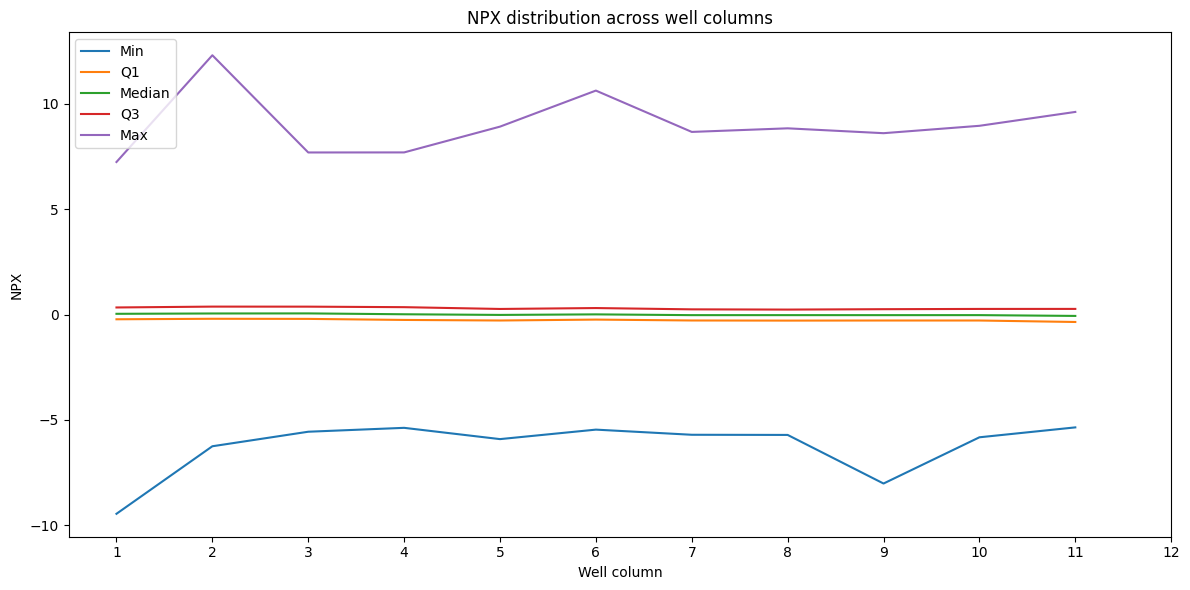

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pro_plate[
    pro_plate["SampleType"].str.lower() == "sample"
].copy()

# WellColごとの要約統計
summary = (
    df.groupby("WellCol")["NPX"]
      .agg(
          min="min",
          Q1=lambda x: x.quantile(0.25),
          median="median",
          Q3=lambda x: x.quantile(0.75),
          max="max"
      )
      .reset_index()
)

# WellColを数値順にする
summary["WellCol"] = pd.to_numeric(summary["WellCol"])
summary = summary.sort_values("WellCol")

# プロット
plt.figure(figsize=(12, 6))

plt.plot(summary["WellCol"], summary["min"], label="Min")
plt.plot(summary["WellCol"], summary["Q1"], label="Q1")
plt.plot(summary["WellCol"], summary["median"], label="Median")
plt.plot(summary["WellCol"], summary["Q3"], label="Q3")
plt.plot(summary["WellCol"], summary["max"], label="Max")

plt.xlabel("Well column")
plt.ylabel("NPX")
plt.title("NPX distribution across well columns")
plt.xticks(range(1, 13))
plt.legend()

plt.tight_layout()
plt.show()

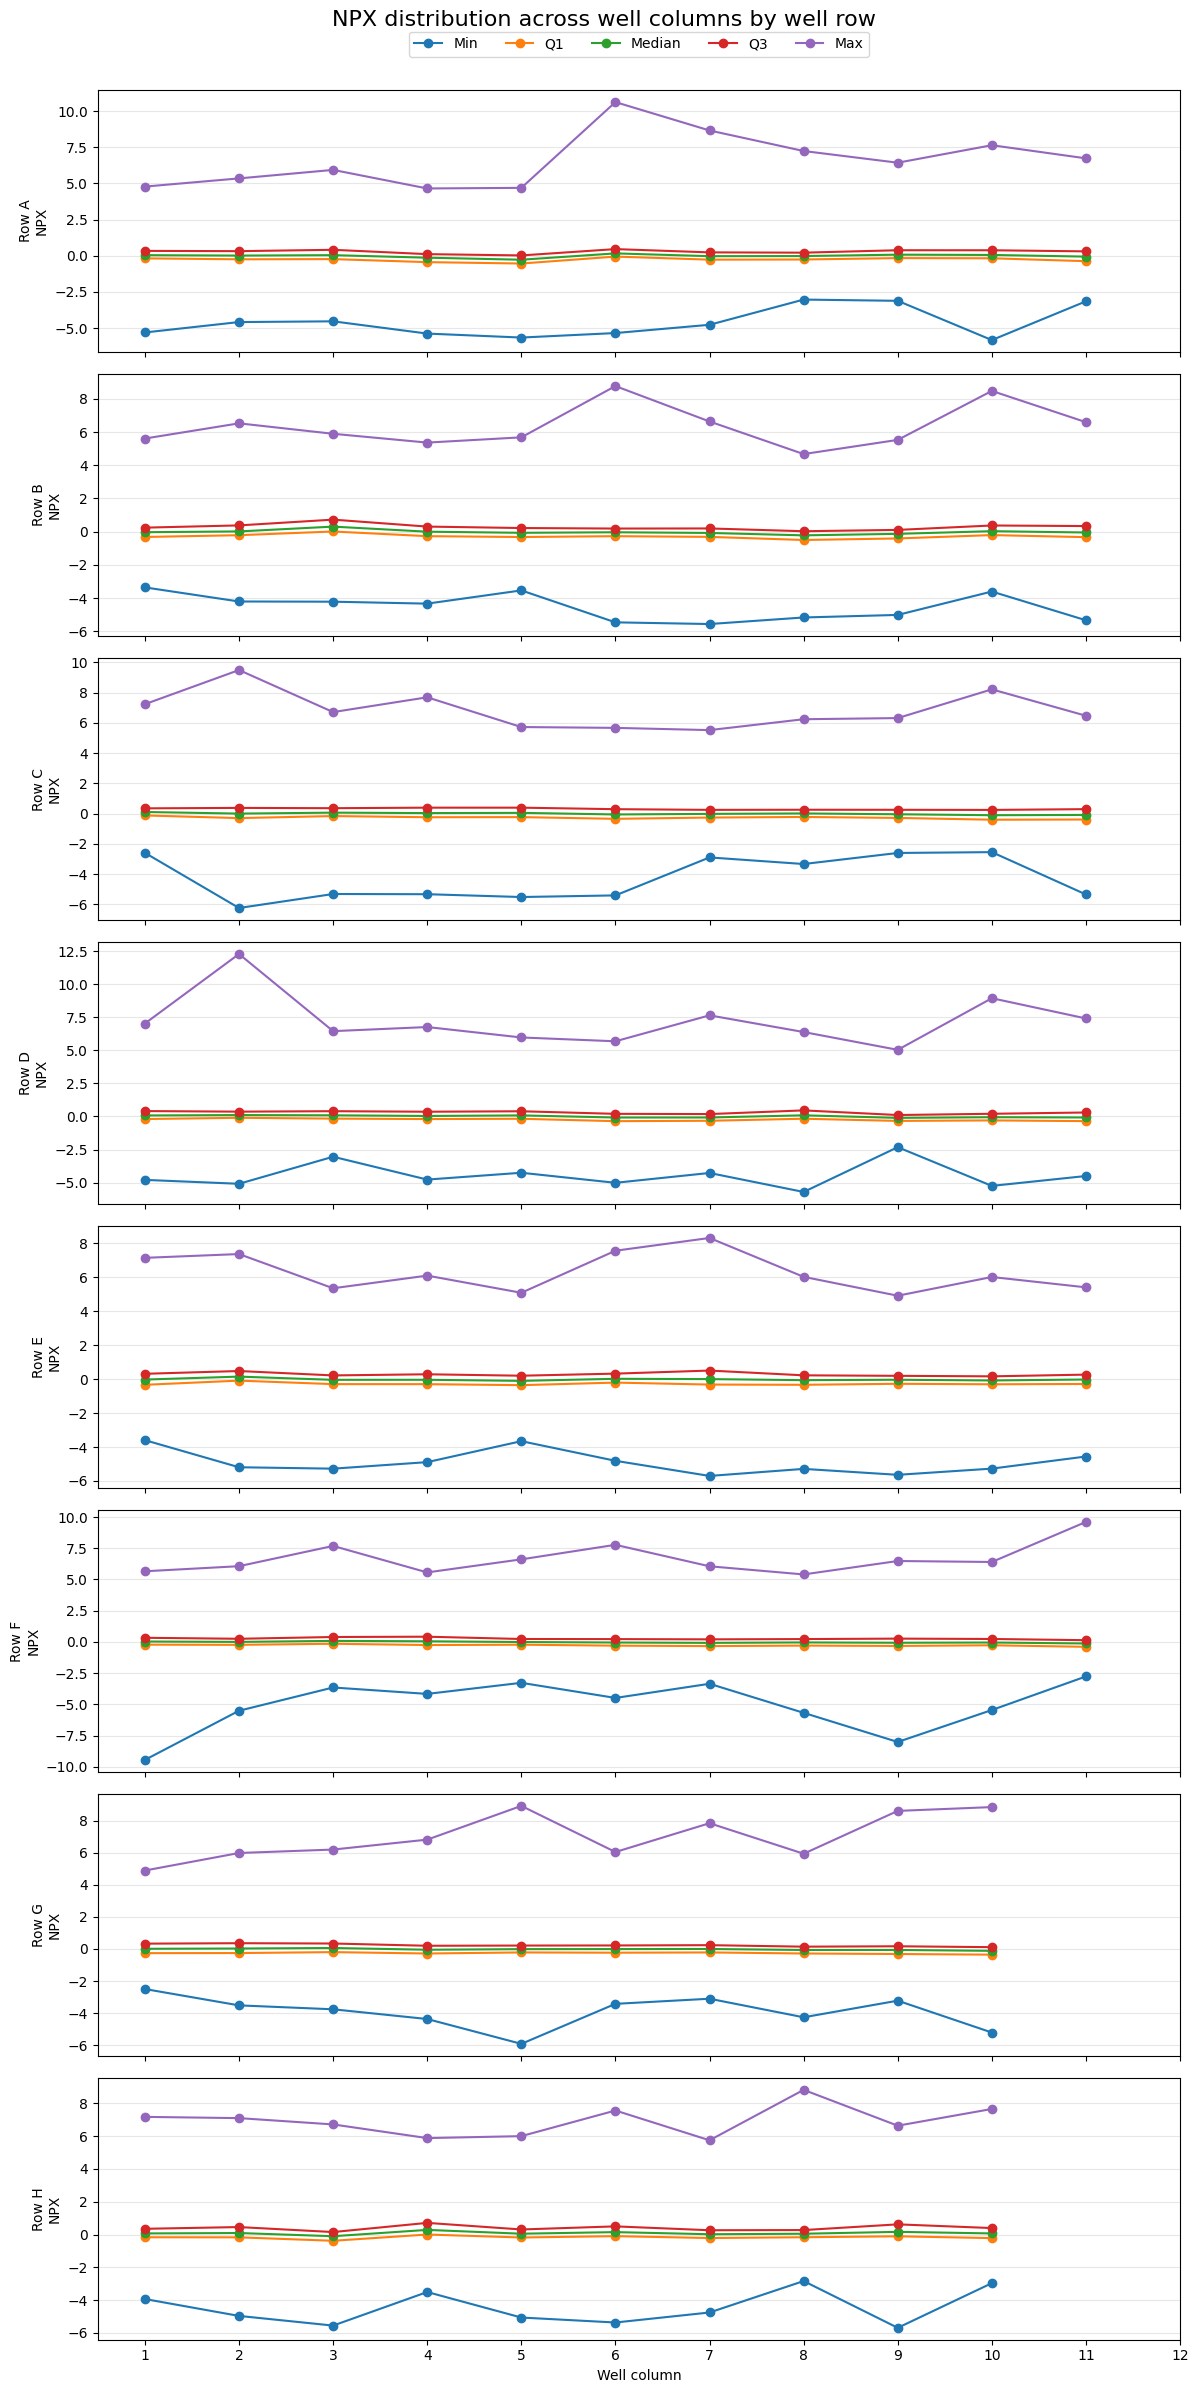

In [24]:

df = pro_plate[
    pro_plate["SampleType"].str.lower() == "sample"
].copy()

# WellColを数値化
df["WellCol"] = pd.to_numeric(df["WellCol"])

# A〜H × 1〜12ごとのNPX要約統計
summary = (
    df.groupby(["WellRow", "WellCol"])["NPX"]
      .agg(
          Min="min",
          Q1=lambda x: x.quantile(0.25),
          Median="median",
          Q3=lambda x: x.quantile(0.75),
          Max="max"
      )
      .reset_index()
)

# A〜Hを順番にプロット
fig, axes = plt.subplots(
    8, 1,
    figsize=(12, 24),
    sharex=True
)

for ax, row in zip(axes, list("ABCDEFGH")):

    temp = summary[summary["WellRow"] == row].sort_values("WellCol")

    ax.plot(temp["WellCol"], temp["Min"], marker="o", label="Min")
    ax.plot(temp["WellCol"], temp["Q1"], marker="o", label="Q1")
    ax.plot(temp["WellCol"], temp["Median"], marker="o", label="Median")
    ax.plot(temp["WellCol"], temp["Q3"], marker="o", label="Q3")
    ax.plot(temp["WellCol"], temp["Max"], marker="o", label="Max")

    ax.set_ylabel(f"Row {row}\nNPX")
    ax.set_xticks(range(1, 13))
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xlabel("Well column")

# 凡例は最上段のみ
axes[0].legend(
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.25)
)

fig.suptitle(
    "NPX distribution across well columns by well row",
    fontsize=16,
    y=0.995
)

plt.tight_layout()
plt.show()

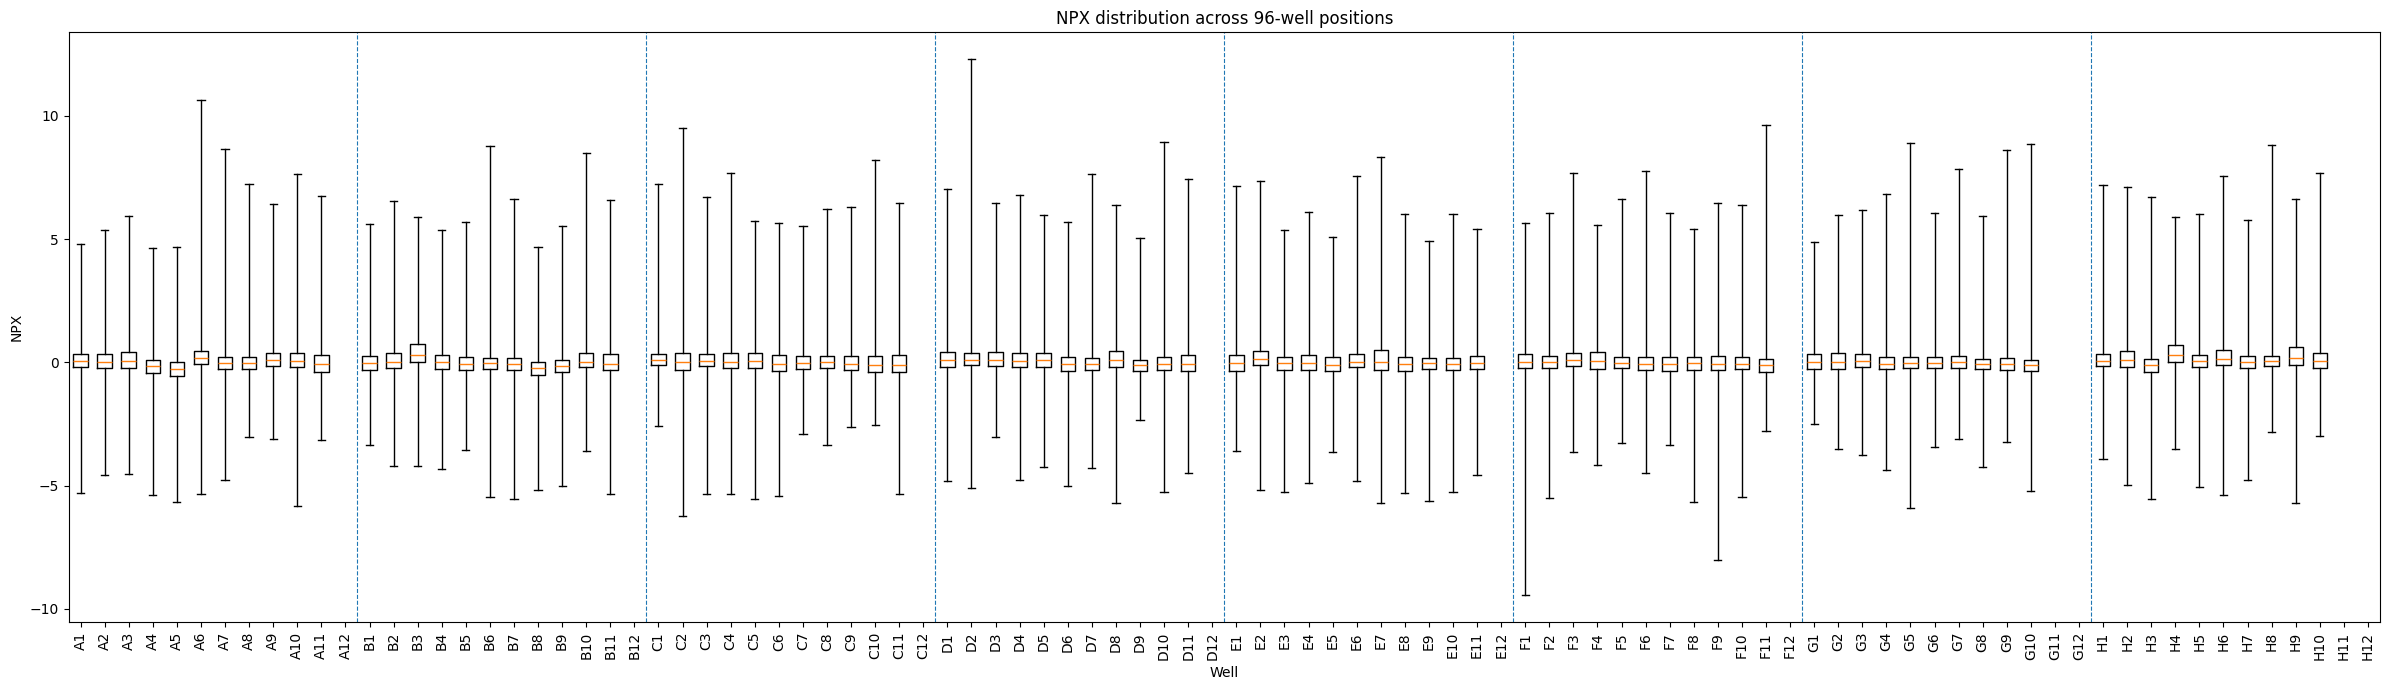

In [28]:

df = pro_plate[
    pro_plate["SampleType"].str.lower() == "sample"
].copy()
df = df.reset_index(drop=True)
# WellColを数値化
df["WellCol"] = pd.to_numeric(df["WellCol"], errors="coerce")

# WellIDを作成
df["Well"] = (
    df["WellRow"].astype(str) +
    df["WellCol"].astype(int).astype(str)
)

# 96 wellの順番
well_order = [
    f"{row}{col}"
    for row in "ABCDEFGH"
    for col in range(1, 13)
]

# 各wellのNPXデータを作成
data = [
    df.loc[df["Well"] == well, "NPX"].dropna().values
    for well in well_order
]

# プロット
fig, ax = plt.subplots(figsize=(24, 7))

ax.boxplot(
    data,
    whis=(0, 100),      # min～max
    showfliers=False,
    widths=0.6
)

# X軸
ax.set_xticks(range(1, 97))
ax.set_xticklabels(well_order, rotation=90)

ax.set_xlabel("Well")
ax.set_ylabel("NPX")
ax.set_title("NPX distribution across 96-well positions")

# Rowごとの区切り
for x in [12.5, 24.5, 36.5, 48.5, 60.5, 72.5, 84.5]:
    ax.axvline(x, linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()

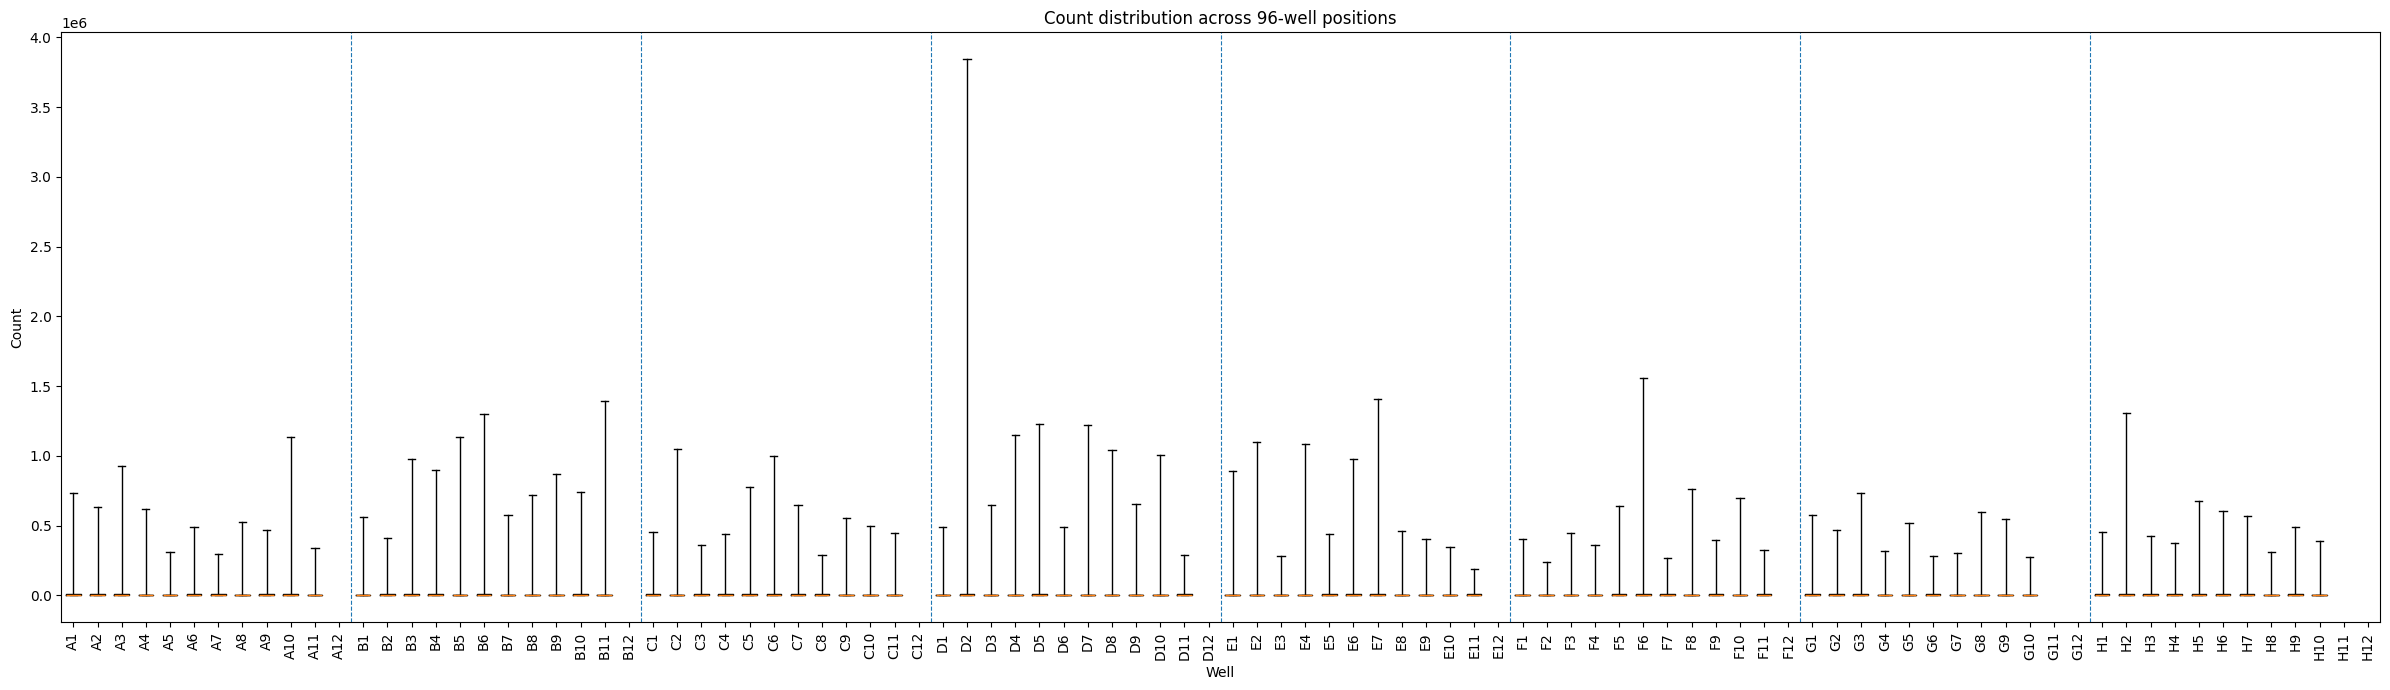

In [29]:

df = pro_plate[
    pro_plate["SampleType"].str.lower() == "sample"
].copy()
df = df.reset_index(drop=True)
# WellColを数値化
df["WellCol"] = pd.to_numeric(df["WellCol"], errors="coerce")

# WellIDを作成
df["Well"] = (
    df["WellRow"].astype(str) +
    df["WellCol"].astype(int).astype(str)
)

# 96 wellの順番
well_order = [
    f"{row}{col}"
    for row in "ABCDEFGH"
    for col in range(1, 13)
]

# 各wellのNPXデータを作成
data = [
    df.loc[df["Well"] == well, "Count"].dropna().values
    for well in well_order
]

# プロット
fig, ax = plt.subplots(figsize=(24, 7))

ax.boxplot(
    data,
    whis=(0, 100),      # min～max
    showfliers=False,
    widths=0.6
)

# X軸
ax.set_xticks(range(1, 97))
ax.set_xticklabels(well_order, rotation=90)

ax.set_xlabel("Well")
ax.set_ylabel("Count")
ax.set_title("Count distribution across 96-well positions")

# Rowごとの区切り
for x in [12.5, 24.5, 36.5, 48.5, 60.5, 72.5, 84.5]:
    ax.axvline(x, linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()